# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді

**1. Чому для заповнення пропусків було обрано метод kNN?**

Проста імпутація (медіана/мода) підставляє в усі пропуски колонки одне й те саме число і не бачить зв'язків між ознаками. kNN-імпутація шукає рядки, схожі за *рештою* ознак, і оцінює пропущене значення за ними, тому заповнення виходить правдоподібнішим: пропуск в `AveRooms` у «великого» будинку заповниться більшим значенням, ніж у «малого». Видалення рядків (drop) тут гірше: пропуски розкидані приблизно по 10% рядків (≈2 064 пропуски на 20 640 рядків), і ми втратили б багато інформації з інших, заповнених колонок. До того ж kNN простий, не робить припущень про форму залежності й підходить для чисельних ознак (а в демо вони всі числові). Щоб не було data leakage, моделі kNN навчаються **лише на train**, а потім застосовуються до train, val і test. Недолік, який я помітив у коді: ознаки перед kNN не стандартизуються, тож відстань визначають колонки з великим масштабом (напр. `Population`).

**2. Чому під час тренування train і val порівнюються лише за MSE, а після тренування — за багатьма метриками?**

MSE є саме тією функцією втрат, яку мінімізує оптимізатор: вона диференційовна й однакова для train і val, тому криві train/val MSE напряму показують, чи модель навчається, чи недонавчена (обидві високі), чи перенавчена (train падає, val росте). Решта метрик відповідає на інші запитання вже *після* тренування: RMSE повертає похибку в одиницях таргету (долари), MAE менше чутлива до викидів, R² показує частку поясненої дисперсії відносно бейзлайну. Для самого навчання вони не потрібні: RMSE монотонно залежить від MSE (крива матиме ту саму форму), R² це перерахована MSE, а MAE негладка в нулі. Рахувати чотири метрики щоепохи — зайве навантаження, а на фінальній оцінці вони допомагають побачити різні аспекти якості.

Щоб перевірити вплив вибору функції втрат, я порівняв `MSELoss`, `L1Loss` (MAE) і `HuberLoss` на лінійній регресії (розділ 2.2.1): кожна функція виграє за «своєю» метрикою. `MSELoss` дає найкращі RMSE і R² (RMSE $6 121, R² 0.759); `L1Loss` дає найкращий MAE ($3 663 проти $4 466), але гірші RMSE ($6 448) і R² (0.732); `HuberLoss` посередині (RMSE $6 153, MAE $4 433, R² 0.756). Висновок: функція втрат має узгоджуватись з метрикою, яка нас цікавить, а на кривих train/val порівнюємо саме ту величину, яку мінімізує оптимізатор (тут MSE).

**3. Які висновки можна зробити після клітинки 2.6 в демо?**

Ознаки стандартизовані, тому модуль ваги напряму показує силу впливу. Найсильніша ознака — `MedInc` (вага ≈ 0.83), далі `diag_coord` (≈ −0.30), `bedperroom` (≈ 0.20) і `HouseAge` (≈ 0.14). Отже, інженерія ознак виправдалась: обидві створені ознаки (`diag_coord`, `bedperroom`) входять у трійку найвагоміших. `Population` має вагу ≈ −0.002, тобто практично не впливає лінійно (це узгоджується з майже нульовою кореляцією в EDA), `AveOccup` також малий (≈ −0.04). Ціна зростає з доходом і зменшується в напрямку діагоналі координат (вглиб країни, далі від узбережжя). Лінійна модель пояснює лише близько 60% дисперсії (R² ≈ 0.60), решта це нелінійні залежності й обрізаний таргет.

**4. Для чого потрібен baseline у лінійній регресії і як він вираховується? Що є baseline для нейромережі?**

Baseline це найпростіший прогноз, з яким порівнюємо модель, щоб побачити, чи вона взагалі чогось навчилась. Для регресії це «завжди прогнозуй середнє значення таргету по **train**» (`y_train.mean()`). Він має R² ≈ 0 (у демо −0.0009) і MSE ≈ дисперсії таргету (1.37). Якщо модель не б'є цей прогноз, вона марна. Для нейромережі baseline це вже натренована лінійна регресія (у демо MSE 0.55 → 0.37 у мережі): мережа виправдана, лише якщо вона перемагає просту лінійну модель, а ще нижче лежить прогноз середнім.

**5. Дія всіх функцій активації на графіку (1000 випадкових X).** Див. клітинку нижче.

**6. Звідки береться кількість параметрів у 3.3?**

У демо 7 вхідних ознак і мережа `7 → 64 → 32 → 1`. Параметрів у кожному `Linear`: ваги `in × out` + зміщення `out`.
- `Linear(7, 64)`: 7·64 + 64 = 512
- `Linear(64, 32)`: 64·32 + 32 = 2 080
- `Linear(32, 1)`: 32·1 + 1 = 33

Разом 512 + 2 080 + 33 = **2 625** (у лінійної моделі всього 7 + 1 = 8, тобто мережа більша приблизно у 330 разів). Активації ReLU параметрів не мають.

**7. Чи оптимально вибрано кількість епох у 3.5?**

Ні. При 200 епохах мінімум val loss досягається саме на останній епосі (199): val MSE ≈ 0.374 і ще повільно падає, як і train (≈ 0.354). Тобто мережа ще недонавчена, а перенавчання немає (train і val йдуть поруч). Оптимальніше тренувати довше з early stopping: зупинятись, коли val loss перестає покращуватись. Це можна й обґрунтувати: 200 епох вибрано «з запасом по часу», а не за кривою навчання.


#### Відповідь на питання 5: графіки функцій активації

Генеруємо 1000 випадкових значень X, рахуємо Y через кожну функцію активації й малюємо точки (Y відносно X).

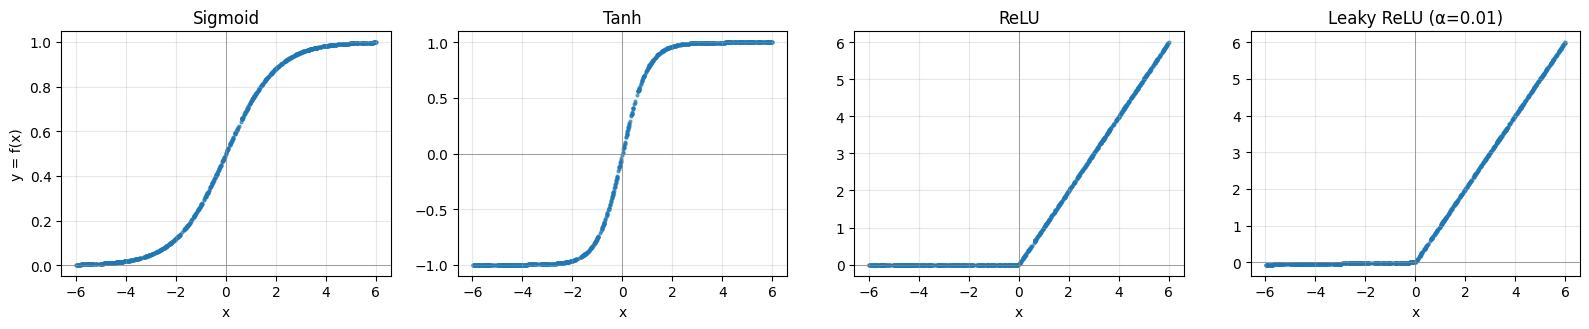

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

rng_act = np.random.default_rng(42)
x_act = torch.tensor(rng_act.uniform(-6, 6, size=1000), dtype=torch.float32)

activations = {
    "Sigmoid": torch.sigmoid,
    "Tanh": torch.tanh,
    "ReLU": torch.relu,
    "Leaky ReLU (α=0.01)": lambda t: torch.nn.functional.leaky_relu(t, negative_slope=0.01),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharex=True)
for ax, (name, fn) in zip(axes, activations.items()):
    y_act = fn(x_act)
    ax.scatter(x_act.numpy(), y_act.numpy(), s=4, alpha=0.6)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(name); ax.set_xlabel("x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("y = f(x)")
plt.tight_layout(); plt.show()

Що видно: **Sigmoid** стискає значення в (0, 1), **Tanh** в (−1, 1), обидві «насичуються» на краях (звідси зникаючий градієнт). **ReLU** обнуляє від'ємні значення й лишає додатні без змін, а **Leaky ReLU** має невеликий нахил (0.01) для від'ємних, тому градієнт там не зникає повністю.

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [2]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Кузьмін Іван Андрійович"  # ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

assert DATASETS[dataset_index] == "Medical Insurance Cost"

Ваш датасет (#9): Medical Insurance Cost


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

---
## Виконання: Medical Insurance Cost (регресія, таргет `charges`)

### 2.0. Налаштування середовища
Ноутбук не прив'язаний до Colab: залежності доставляються автоматично, артефакти пишуться у відносні папки `runs/` і `models/`, `results.csv` лежить поруч із ноутбуком. Тренуємо на CPU (дані й моделі дрібні, 1 338 рядків).

In [3]:
import os, sys, random, shutil, subprocess, importlib.util

os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")
for pkg, pip_name in [("datasets", "datasets"), ("tensorboard", "tensorboard"),
                      ("gradio", "gradio"), ("sklearn", "scikit-learn"),
                      ("seaborn", "seaborn"), ("scipy", "scipy")]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

IN_COLAB = "google.colab" in sys.modules
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cpu")

RUNS_DIR = "runs"
MODELS_DIR = "models"
for d in (RUNS_DIR, MODELS_DIR):          # чистий старт: щоб повторний запуск не дублював логи
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d)
print("Використовуємо:", device, "| Colab:", IN_COLAB)

Використовуємо: cpu | Colab: False


### 2.1. Підготовка даних

#### Завантаження та перетворення на DataFrame (демо 1.1–1.2)

In [4]:
from datasets import load_dataset

raw = load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")
print(raw)
df = raw["train"].to_pandas()
print("Розмір таблиці:", df.shape)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
        num_rows: 1338
    })
})
Розмір таблиці: (1338, 7)


#### Спліт train / val / test одразу, до будь-якого аналізу (демо 1.3)

Спліт робимо **першим кроком**, до `describe()`, кореляцій, пошуку викидів і будь-яких статистик. Інакше інформація про val/test (середні, розподіли, кореляції, «дивні» рядки) непомітно вплине на наші рішення щодо ознак, кодування чи викидів, а це **data leakage**: метрики виглядатимуть краще, ніж модель працюватиме на нових даних. Усі рішення нижче приймаємо тільки за `train`, а val і test лишаються «як є». Пропорція 60/20/20, як у демо.

In [5]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.4, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print(f"train: {train_df.shape}  val: {val_df.shape}  test: {test_df.shape}")

# Чи є дублікати рядків і де вони опинились?
dups = df[df.duplicated(keep=False)]
print("\nДублікати в усьому датасеті:", len(dups), "рядків")
print("Індекси в train/val/test:", {
    "train": int(dups.index.isin(train_df.index).sum()),
    "val": int(dups.index.isin(val_df.index).sum()),
    "test": int(dups.index.isin(test_df.index).sum())})

train: (802, 7)  val: (268, 7)  test: (268, 7)

Дублікати в усьому датасеті: 2 рядків
Індекси в train/val/test: {'train': 1, 'val': 0, 'test': 1}


У датасеті є одна пара ідентичних рядків (можливо, збіг двох різних людей, можливо, дубль у джерелі), і вона розділилась між train і test: один тестовий рядок має точну копію в train. Це 1 рядок із 268 у test, тому вплив на метрики мізерний. Нічого не видаляємо: test лишаємо «як є», а видалення одного рядка з train нічого не змінило б по суті.

#### Загальний огляд (демо 1.4): тільки `train`

In [6]:
train_df.head()

,age,sex,bmi,children,smoker,region,charges
25,59,female,27.72,3,no,southeast,14001.1338
336,60,male,25.74,0,no,southeast,12142.5786
47,28,female,34.77,0,no,northwest,3556.9223
106,19,female,28.40,1,no,southwest,2331.5190
1269,45,male,27.50,3,no,southwest,8615.3000


In [7]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 802 entries, 25 to 1126
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       802 non-null    int64  
 1   sex       802 non-null    str    
 2   bmi       802 non-null    float64
 3   children  802 non-null    int64  
 4   smoker    802 non-null    str    
 5   region    802 non-null    str    
 6   charges   802 non-null    float64
dtypes: float64(2), int64(2), str(3)
memory usage: 63.1 KB


In [8]:
train_df.describe()

,age,bmi,children,charges
count,802.000000,802.000000,802.000000,802.000000
mean,39.245636,30.422101,1.098504,13297.764279
std,14.233588,5.965236,1.198844,12040.598471
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.180000,0.000000,4828.586213
50%,39.000000,30.127500,1.000000,9502.441675
75%,52.000000,34.422500,2.000000,16791.384968
max,64.000000,53.130000,5.000000,62592.873090


#### Пропуски (демо 1.5)

In [9]:
print("Пропуски в train:\n", train_df.isna().sum(), sep="")
print("\nУсього пропусків: train =", int(train_df.isna().sum().sum()),
      "| val =", int(val_df.isna().sum().sum()),
      "| test =", int(test_df.isna().sum().sum()))
print("\nУнікальні значення категоріальних колонок (train):")
for c in ["sex", "smoker", "region"]:
    print(f"  {c}: {sorted(train_df[c].unique())}")

Пропуски в train:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Усього пропусків: train = 0 | val = 0 | test = 0

Унікальні значення категоріальних колонок (train):
  sex: ['female', 'male']
  smoker: ['no', 'yes']
  region: ['northeast', 'northwest', 'southeast', 'southwest']


**Пропусків немає** ні в train, ні у val/test, а в категоріальних колонках немає прихованих «порожніх» міток (`?`, `unknown` тощо). Тому імпутація не потрібна. Штучно пропуски не вигадуємо (як і наказує умова лаби).

#### EDA (демо 1.6): тільки `train`

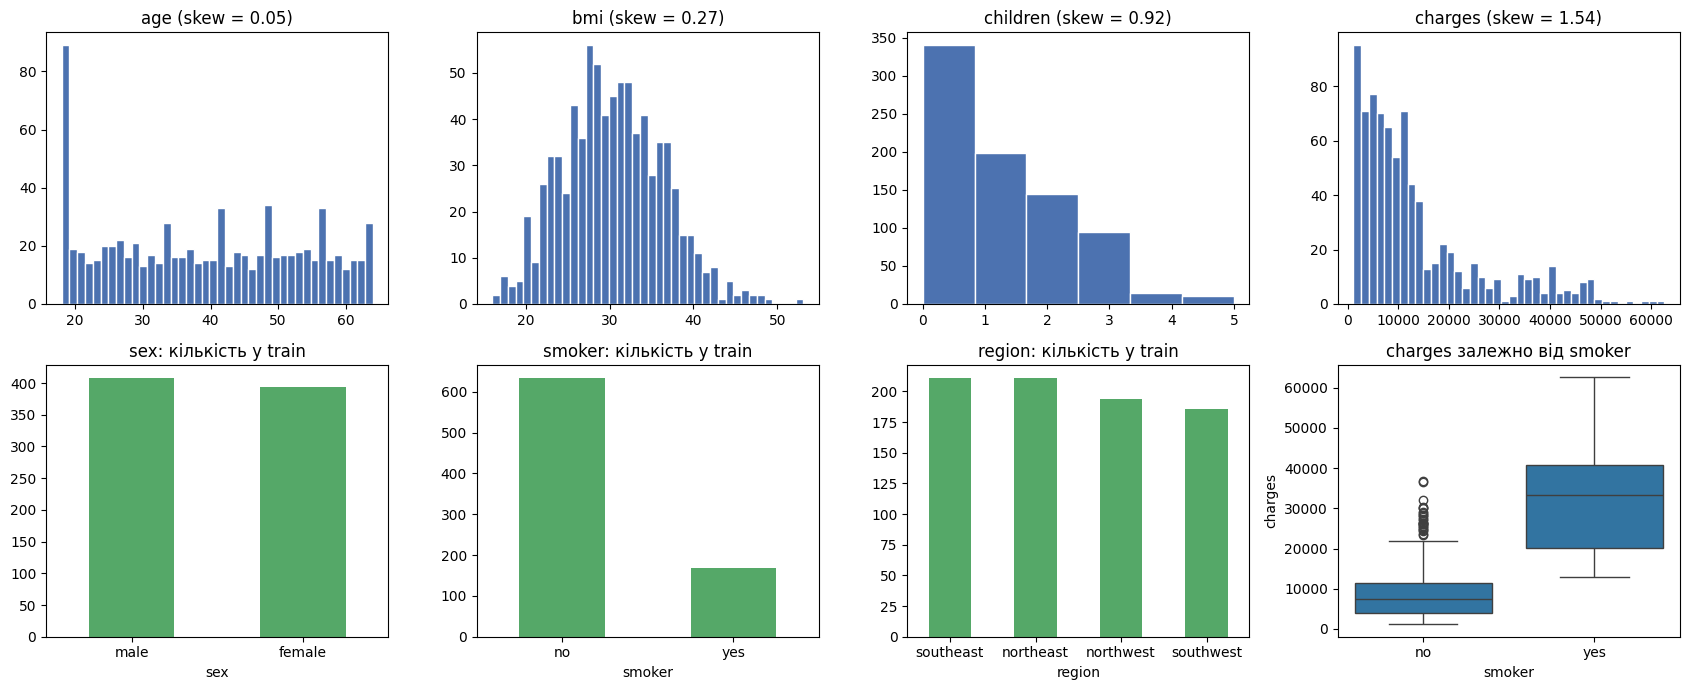

In [10]:
from scipy.stats import skew

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes[0], ["age", "bmi", "children", "charges"]):
    ax.hist(train_df[col], bins=40 if col != "children" else 6, color="#4C72B0", edgecolor="white")
    ax.set_title(f"{col} (skew = {skew(train_df[col]):.2f})")
for ax, col in zip(axes[1][:3], ["sex", "smoker", "region"]):
    train_df[col].value_counts().plot.bar(ax=ax, color="#55A868", rot=0)
    ax.set_title(f"{col}: кількість у train")
sns.boxplot(data=train_df, x="smoker", y="charges", ax=axes[1][3])
axes[1][3].set_title("charges залежно від smoker")
plt.tight_layout(); plt.show()

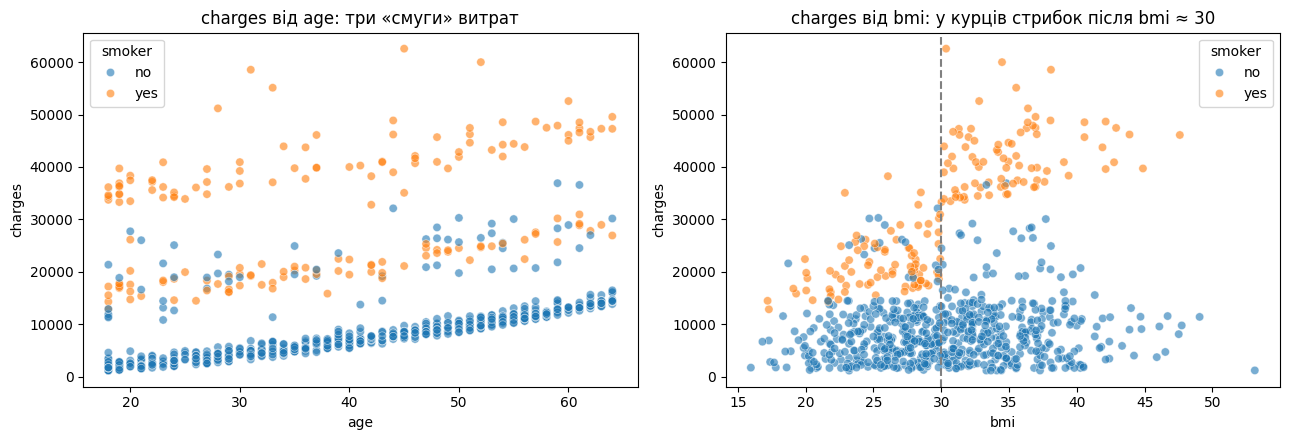

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=train_df, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
axes[0].set_title("charges від age: три «смуги» витрат")
sns.scatterplot(data=train_df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
axes[1].axvline(30, color="gray", ls="--"); axes[1].set_title("charges від bmi: у курців стрибок після bmi ≈ 30")
plt.tight_layout(); plt.show()

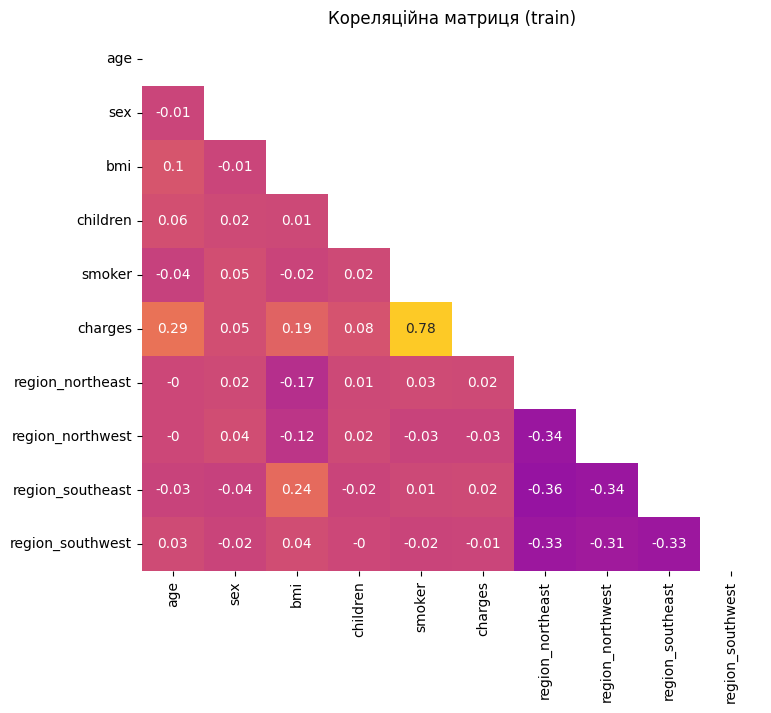

Кореляція з charges:
smoker              0.78
age                 0.29
bmi                 0.19
children            0.08
sex                 0.05
region_northeast    0.02
region_southeast    0.02
region_southwest   -0.01
region_northwest   -0.03
Name: charges, dtype: float64


In [12]:
# Кодуємо категорії лише для кореляційної матриці (повне кодування для моделі: у 2.2)
enc_eda = train_df.copy()
enc_eda["sex"] = (enc_eda["sex"] == "male").astype(int)
enc_eda["smoker"] = (enc_eda["smoker"] == "yes").astype(int)
enc_eda = pd.get_dummies(enc_eda, columns=["region"], dtype=int)

corr = enc_eda.corr().round(2)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 7))
sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, center=0, cmap="plasma", annot=True, cbar=False)
plt.title("Кореляційна матриця (train)"); plt.show()

print("Кореляція з charges:")
print(corr["charges"].drop("charges").sort_values(ascending=False))

**Що впадає в очі:**

- **Таргет `charges` скошений праворуч** (skew ≈ 1.5): довгий хвіст дорогих випадків. Дані не обрізані (capping): піку на максимумі немає, топ-значення всі різні (перевіряємо нижче).
- **`smoker` домінує:** кореляція з `charges` ≈ 0.78, у курців витрати в середньому в ≈ 3.7 раза вищі. Інші ознаки з таргетом корелюють слабо: `age` ≈ 0.29, `bmi` ≈ 0.19, `children` ≈ 0.08, `sex` ≈ 0.05, регіони ≈ 0.
- **Нелінійність (взаємодія):** на scatter `bmi → charges` у курців видно стрибок витрат при `bmi ≥ 30`, а у некурців такого немає. Лінійна модель із сумою «внесків» такої взаємодії не бачить, а нейромережа в принципі може її вивчити.
- **Мультиколінеарності немає:** ознаки між собою майже не корелюють (регіональні «дамі» мають помірну від'ємну кореляцію між собою просто за побудовою one-hot). Об'єднувати чи викидати пари нема потреби.

#### Обробка викидів (демо 1.7): вирішуємо за причиною виникнення

In [13]:
# 1) Чи є «capping» (штучне обрізання)? Дивимось, чи є неприродні піки на межах.
print("age: найбільші значення та кількість рядків:")
print(train_df["age"].value_counts().sort_index(ascending=False).head(5).to_dict())
print("\ncharges: 5 найбільших значень (усі різні, піку немає):")
print(train_df["charges"].nlargest(5).round(2).tolist())
print("\nbmi: 6 найбільших значень:", train_df["bmi"].nlargest(6).tolist())
print("children: розподіл:", train_df["children"].value_counts().sort_index().to_dict())

# 2) «Викиди» за правилом 1.5·IQR для charges: хто це?
q1, q3 = train_df["charges"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
flagged = train_df[train_df["charges"] > upper]
print(f"\ncharges > {upper:,.0f} (поріг 1.5·IQR): {len(flagged)} рядків із {len(train_df)}")
print(f"Серед них курців: {(flagged['smoker'] == 'yes').mean():.0%}, у середньому bmi = {flagged['bmi'].mean():.1f}")

age: найбільші значення та кількість рядків:
{64: 14, 63: 14, 62: 15, 61: 15, 60: 12}

charges: 5 найбільших значень (усі різні, піку немає):
[62592.87, 60021.4, 58571.07, 55135.4, 52590.83]

bmi: 6 найбільших значень: [53.13, 49.06, 47.74, 47.6, 47.52, 46.7]
children: розподіл: {0: 340, 1: 198, 2: 144, 3: 95, 4: 15, 5: 10}

charges > 34,736 (поріг 1.5·IQR): 78 рядків із 802
Серед них курців: 97%, у середньому bmi = 35.2


**Рішення: викиди не видаляємо.**

- **Capping немає.** `age` закінчується на 64 без піку (сусідні значення мають схожу кількість рядків), `charges` не має «стелі» (найбільші значення всі різні), тож ані ознаки, ані таргет не обрізані.
- **Помилок запису теж не видно.** `bmi` до 53 це хоч і екстремальне, але фізично можливе значення (тяжке ожиріння), `children` до 5, вік 18–64: усе правдоподібно.
- **«Викиди» за IQR для `charges` це реальні рідкісні спостереження**: переважно курці з високим `bmi`, тобто саме той сегмент, у якому вартість лікування об'єктивно найвища. Видалення таких рядків зробило б модель сліпою до найдорожчих випадків (а вони важливі для страховика), тому видаляти небезпечно. Трансформації (напр. `log(charges)`) теж не застосовуємо: це змінило б одиниці таргету й ускладнило б чесне порівняння метрик; натомість стандартизуємо таргет (2.2), що вирішує проблему масштабу для градієнтного спуску.
- Правило демо: чистити можна було б тільки train, а val і test лишати без змін. Тут чистити нічого не потрібно.

#### Інженерія ознак (демо 1.8)

In [14]:
print("Середній charges за комбінацією smoker × (bmi ≥ 30), train:")
print(train_df.assign(obese=train_df["bmi"] >= 30)
      .groupby(["smoker", "obese"])["charges"].mean().round(0).unstack())

Середній charges за комбінацією smoker × (bmi ≥ 30), train:
obese     False    True 
smoker                  
no       7835.0   9094.0
yes     21426.0  42005.0


Взаємодія є: для курців із `bmi ≥ 30` середні витрати ≈ вдвічі вищі, ніж для курців із меншим `bmi`, а у некурців різниця невелика.

**Рішення:** відомих пар сильно корельованих ознак немає, тому нічого не об'єднуємо й не прибираємо. Колонку `region` лишаємо, хоч кореляція з таргетом майже нульова: низька *лінійна* кореляція не означає, що ознака марна (так само, як у демо з `AveOccup`). Взаємодію `smoker × obese` свідомо **не додаємо** як ознаку: так порівняння «лінійна регресія проти нейромережі» перевіряє, чи здатна мережа відкрити таку залежність самостійно. Як контроль, у 2.5.1 перевіряємо, наскільки лінійна модель покращилась би, якби цю ознаку додати вручну.

### 2.2. Baseline: множинна лінійна регресія

#### Кодування, стандартизація, тензори (демо 2.1–2.2)

- `sex` і `smoker` (бінарні): 0/1; `region` (номінальна, 4 значення): one-hot без однієї категорії (`northeast` лишається «базовою»), щоб не було ідеальної лінійної залежності між колонками.
- Усі ознаки стандартизуємо `StandardScaler`, статистики рахуємо **тільки на train**.
- **Таргет теж стандартизуємо** (теж лише за train): `charges` має масштаб ~10⁴, і MSE у доларах² було б ~10⁸, а градієнтний спуск на такому масштабі розходиться чи надто повільний. Усі лоси й криві нижче в «стандартизованих» одиницях, а *метрики на test рахуємо в доларах*, повернувши прогноз у вихідний масштаб (`inverse_transform`).

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

REGIONS = sorted(train_df["region"].unique())          # категорії беремо з train

def encode(d: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame({
        "age": d["age"].astype(float),
        "bmi": d["bmi"].astype(float),
        "children": d["children"].astype(float),
        "sex_male": (d["sex"] == "male").astype(float),
        "smoker_yes": (d["smoker"] == "yes").astype(float),
    })
    for r in REGIONS[1:]:                               # першу категорію (northeast) відкидаємо
        out[f"region_{r}"] = (d["region"] == r).astype(float)
    return out

feature_cols = list(encode(train_df).columns)
x_scaler, y_scaler = StandardScaler(), StandardScaler()

X_train = x_scaler.fit_transform(encode(train_df))      # fit тільки на train
X_val = x_scaler.transform(encode(val_df))
X_test = x_scaler.transform(encode(test_df))
y_train = y_scaler.fit_transform(train_df[["charges"]])
y_val = y_scaler.transform(val_df[["charges"]])
y_test = y_scaler.transform(test_df[["charges"]])

def to_t(a):
    return torch.tensor(a, dtype=torch.float32).to(device)

x_train_t, y_train_t = to_t(X_train), to_t(y_train)
x_val_t, y_val_t = to_t(X_val), to_t(y_val)
x_test_t, y_test_t = to_t(X_test), to_t(y_test)

y_test_usd = test_df["charges"].values                  # справжні значення в доларах
print("Ознаки:", feature_cols)
print("X_train:", tuple(x_train_t.shape), "| y_train:", tuple(y_train_t.shape))

Ознаки: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
X_train: (802, 8) | y_train: (802, 1)


#### Інфраструктура для всіх варіантів

Усі варіанти (лінійна модель та нейромережі) тренуємо однією функцією, щоб відрізнялись лише ті параметри, які ми свідомо змінюємо. Кожен варіант: окрема підпапка в `runs/` (TensorBoard), окремий файл у `models/`, окремий рядок у таблиці результатів. Криві train/val завжди рахуємо як MSE у повному train/val (в `eval`-режимі), тому вони порівнянні між варіантами, навіть якщо тренування йшло міні-батчами.

In [16]:
from torch.utils.tensorboard import SummaryWriter
from IPython.display import display

mse_loss = torch.nn.MSELoss()
trained, histories, all_rows = {}, {}, []

def make_mlp(n_in, hidden, activation="relu"):
    act = {"relu": torch.nn.ReLU, "tanh": torch.nn.Tanh}[activation]
    layers, prev = [], n_in
    for h in hidden:
        layers += [torch.nn.Linear(prev, h), act()]
        prev = h
    layers.append(torch.nn.Linear(prev, 1))              # вихід без активації (регресія)
    return torch.nn.Sequential(*layers)

def make_optimizer(name, params, lr):
    return {"adam": torch.optim.Adam, "sgd": torch.optim.SGD}[name](params, lr=lr)

def predict_usd(model, x_t):
    model.eval()
    with torch.no_grad():
        p = model(x_t).cpu().numpy()
    return y_scaler.inverse_transform(p).ravel()

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": mse ** 0.5,
            "MAE": mean_absolute_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

def train_variant(name, spec, log=True, train_loss_fn=None, seed=SEED):
    """spec: hidden, activation, optimizer, lr, epochs, batch_size (None = весь train за крок)."""
    set_seed(seed)                                       # однакова ініціалізація й перемішування для чесного порівняння
    model = make_mlp(x_train_t.shape[1], spec["hidden"], spec["activation"]).to(device)
    opt = make_optimizer(spec["optimizer"], model.parameters(), spec["lr"])
    loss_fn = train_loss_fn or mse_loss
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, name)) if log else None
    hist = {"train": [], "val": []}
    n = len(x_train_t)
    for epoch in range(spec["epochs"]):
        model.train()
        if spec["batch_size"] is None:
            opt.zero_grad(); loss_fn(model(x_train_t), y_train_t).backward(); opt.step()
        else:
            perm = torch.randperm(n)
            for i in range(0, n, spec["batch_size"]):
                idx = perm[i:i + spec["batch_size"]]
                opt.zero_grad(); loss_fn(model(x_train_t[idx]), y_train_t[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            tl = mse_loss(model(x_train_t), y_train_t).item()
            vl = mse_loss(model(x_val_t), y_val_t).item()
        hist["train"].append(tl); hist["val"].append(vl)
        if writer:
            writer.add_scalar("Loss/train", tl, epoch); writer.add_scalar("Loss/val", vl, epoch)
    if writer:
        writer.close()
    return model, hist

def save_model(name, model, spec):
    torch.save({"state_dict": model.state_dict(), "hidden": spec["hidden"],
                "activation": spec["activation"], "feature_cols": feature_cols,
                "n_in": len(feature_cols)}, os.path.join(MODELS_DIR, f"{name}.pt"))

def run_variant(name, spec, note):
    model, hist = train_variant(name, spec)
    save_model(name, model, spec)
    trained[name], histories[name] = model, hist
    m_test = regression_metrics(y_test_usd, predict_usd(model, x_test_t))
    all_rows.append({"model": name, "change": note, "val_MSE(std)": hist["val"][-1],
                     "best_val_epoch": int(np.argmin(hist["val"])) + 1, "epochs": spec["epochs"], **m_test})
    r = all_rows[-1]
    print(f"{name:22s} val_MSE(std)={r['val_MSE(std)']:.4f} | test: RMSE=${r['RMSE']:,.0f}  MAE=${r['MAE']:,.0f}  R2={r['R2']:.4f}")
    return model

#### Тренуємо лінійну регресію (демо 2.3–2.5)

`nn.Linear(8 → 1)` (у коді це `Sequential` з одним `Linear`), MSE, SGD lr = 0.1. Кількість епох (300) обрано за кривою навчання: на ній loss виходить на плато. Як перевірку коректності порівнюємо результат із точним (аналітичним) розв'язком МНК із `sklearn`.

In [17]:
LINEAR_SPEC = dict(hidden=[], activation="relu", optimizer="sgd", lr=0.1, epochs=300, batch_size=None)
linear_model = run_variant("linear", LINEAR_SPEC, "baseline: множинна лінійна регресія")

# Бейзлайн-прогноз: середнє train (у доларах)
baseline_pred = np.full_like(y_test_usd, train_df["charges"].mean())
print("\nБейзлайн (середнє train):", {k: round(v, 4) for k, v in regression_metrics(y_test_usd, baseline_pred).items()})

linear                 val_MSE(std)=0.2315 | test: RMSE=$6,121  MAE=$4,466  R2=0.7585

Бейзлайн (середнє train): {'MSE': 156133561.455, 'RMSE': 12495.3416, 'MAE': 9475.2467, 'R2': -0.0066}


МНК (sklearn): {'MSE': 37466275.9569, 'RMSE': 6120.9702, 'MAE': 4465.5027, 'R2': 0.7585}
SGD (PyTorch): {'MSE': 37466276.6433, 'RMSE': 6120.9702, 'MAE': 4465.5025, 'R2': 0.7585}


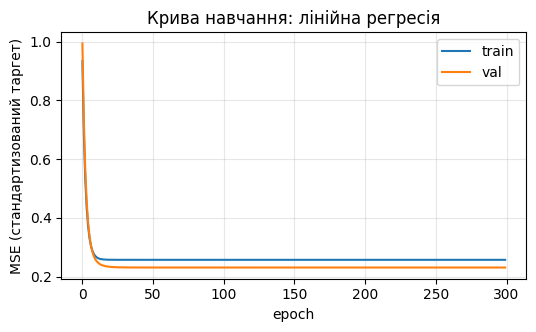

In [18]:
from sklearn.linear_model import LinearRegression

ols = LinearRegression().fit(X_train, y_train)          # точний розв'язок МНК на тих самих даних
ols_pred = y_scaler.inverse_transform(ols.predict(X_test)).ravel()
print("МНК (sklearn):", {k: round(v, 4) for k, v in regression_metrics(y_test_usd, ols_pred).items()})
print("SGD (PyTorch):", {k: round(v, 4) for k, v in regression_metrics(y_test_usd, predict_usd(linear_model, x_test_t)).items()})

plt.figure(figsize=(6, 3.2))
plt.plot(histories["linear"]["train"], label="train"); plt.plot(histories["linear"]["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE (стандартизований таргет)"); plt.title("Крива навчання: лінійна регресія")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [19]:
# Інтерпретація ваг (демо 2.6): ознаки стандартизовані, тому |вага| = сила впливу
w = linear_model[0].weight.detach().numpy().ravel()
weights_df = pd.DataFrame({"feature": feature_cols, "weight": w})
print(weights_df.reindex(weights_df["weight"].abs().sort_values(ascending=False).index).to_string(index=False))

         feature    weight
      smoker_yes  0.791852
             age  0.306981
             bmi  0.175258
        children  0.042712
region_southeast -0.033289
region_southwest -0.026799
        sex_male  0.010736
region_northwest -0.006827


**Інтерпретація ваг:** ознаки й таргет стандартизовані, тож модуль ваги показує силу впливу. Однозначно домінує `smoker_yes` (≈ +0.79 стандартного відхилення таргету), далі `age` (≈ +0.31) і `bmi` (≈ +0.18). `children` впливає слабко (≈ +0.04), а `sex_male` і регіональні колонки близькі до нуля (|вага| ≤ 0.03), що узгоджується з майже нульовими кореляціями в EDA. Знаки логічні: старші люди, курці та люди з вищим ІМТ мають вищі витрати. Проте лінійна модель складає внески ознак окремо й не бачить взаємодії `smoker × bmi`, яку ми помітили в EDA.

#### 2.2.1. Експеримент до питання 2: вибір функції втрат

Тренуємо ту саму лінійну модель (ті самі дані, ініціалізація, оптимізатор і число епох), змінюючи лише функцію втрат. Це допоміжний експеримент, у `results.csv` і `runs/` він не потрапляє. Метрики на test у доларах.

In [20]:
loss_experiment = {
    "MSELoss": torch.nn.MSELoss(),
    "L1Loss (MAE)": torch.nn.L1Loss(),
    "HuberLoss (δ=1)": torch.nn.HuberLoss(delta=1.0),
}
rows = []
for lname, lfn in loss_experiment.items():
    m_, _ = train_variant("tmp", LINEAR_SPEC, log=False, train_loss_fn=lfn)
    rows.append({"loss": lname, **regression_metrics(y_test_usd, predict_usd(m_, x_test_t))})
loss_exp_df = pd.DataFrame(rows).set_index("loss")
loss_exp_df.round(4)

,MSE,RMSE,MAE,R2
loss,,,,
MSELoss,3.746628e+07,6120.9702,4465.5025,0.7585
L1Loss (MAE),4.158273e+07,6448.4675,3662.6859,0.7319
HuberLoss (δ=1),3.785975e+07,6153.0276,4433.4215,0.7559


### 2.3. Нейромережа: три різні архітектури (демо 3.2–3.7)

Усі: ReLU/Tanh у прихованих шарах, вихід без активації, Adam, lr = 0.01, 200 епох, повний train за крок. Відрізняються *структурою*, а не косметикою:

| варіант | приховані шари | активація | чим відрізняється |
|---|---|---|---|
| `nn_v1` | 64 → 32 | ReLU | відправна точка (як у демо) |
| `nn_v2` | 128 → 64 → 32 | ReLU | глибша й ширша |
| `nn_v3` | 64 → 32 | Tanh | та сама форма, інша активація |

In [21]:
BASE = dict(optimizer="adam", lr=0.01, epochs=200, batch_size=None)
ARCHS = {
    "nn_v1": dict(hidden=[64, 32], activation="relu", **BASE),
    "nn_v2": dict(hidden=[128, 64, 32], activation="relu", **BASE),
    "nn_v3": dict(hidden=[64, 32], activation="tanh", **BASE),
}
notes = {"nn_v1": "архітектура 64-32, ReLU", "nn_v2": "архітектура 128-64-32, ReLU", "nn_v3": "архітектура 64-32, Tanh"}
for name, spec in ARCHS.items():
    run_variant(name, spec, notes[name])
    print("   параметрів:", sum(p.numel() for p in trained[name].parameters()))

nn_v1                  val_MSE(std)=0.1737 | test: RMSE=$5,087  MAE=$3,328  R2=0.8332
   параметрів: 2689


nn_v2                  val_MSE(std)=0.1772 | test: RMSE=$5,508  MAE=$3,379  R2=0.8044
   параметрів: 11521


nn_v3                  val_MSE(std)=0.1670 | test: RMSE=$5,264  MAE=$3,315  R2=0.8214
   параметрів: 2689


### 2.4. Підбір гіперпараметрів: по одній зміні за раз

Беремо архітектуру з найменшим **val** MSE (за val, а не за test: test лишається для фінальної чесної оцінки) і змінюємо від її базових налаштувань (Adam, lr = 0.01, 200 епох, повний train за крок) рівно один параметр за варіант.

In [22]:
arch_val = {n: histories[n]["val"][-1] for n in ARCHS}
best_arch = min(arch_val, key=arch_val.get)
print("val MSE архітектур:", {k: round(v, 4) for k, v in arch_val.items()})
print("Найкраща архітектура за val:", best_arch)

best_spec = ARCHS[best_arch]
HYPER = {
    f"{best_arch}_lr_0.001":     ({**best_spec, "lr": 0.001},        "lr: 0.01 → 0.001"),
    f"{best_arch}_sgd":          ({**best_spec, "optimizer": "sgd"}, "оптимізатор: Adam → SGD (lr 0.01)"),
    f"{best_arch}_epochs_500":   ({**best_spec, "epochs": 500},      "епохи: 200 → 500"),
    f"{best_arch}_batch_64":     ({**best_spec, "batch_size": 64},   "батч: весь train → 64"),
}
print()
for name, (spec, note) in HYPER.items():
    run_variant(name, spec, note)

val MSE архітектур: {'nn_v1': 0.1737, 'nn_v2': 0.1772, 'nn_v3': 0.167}
Найкраща архітектура за val: nn_v3



nn_v3_lr_0.001         val_MSE(std)=0.1541 | test: RMSE=$4,919  MAE=$3,034  R2=0.8440


nn_v3_sgd              val_MSE(std)=0.2387 | test: RMSE=$6,186  MAE=$4,394  R2=0.7533


nn_v3_epochs_500       val_MSE(std)=0.2771 | test: RMSE=$7,211  MAE=$4,880  R2=0.6647


nn_v3_batch_64         val_MSE(std)=0.2524 | test: RMSE=$6,386  MAE=$4,267  R2=0.7371


### 2.5. Логування і порівняння

Усі прогони залоговані в TensorBoard (`runs/<назва варіанта>`). Щоб побачити їх накладеними, запустіть `tensorboard --logdir runs` (у Colab нижче підключається автоматично).

Локально: tensorboard --logdir runs


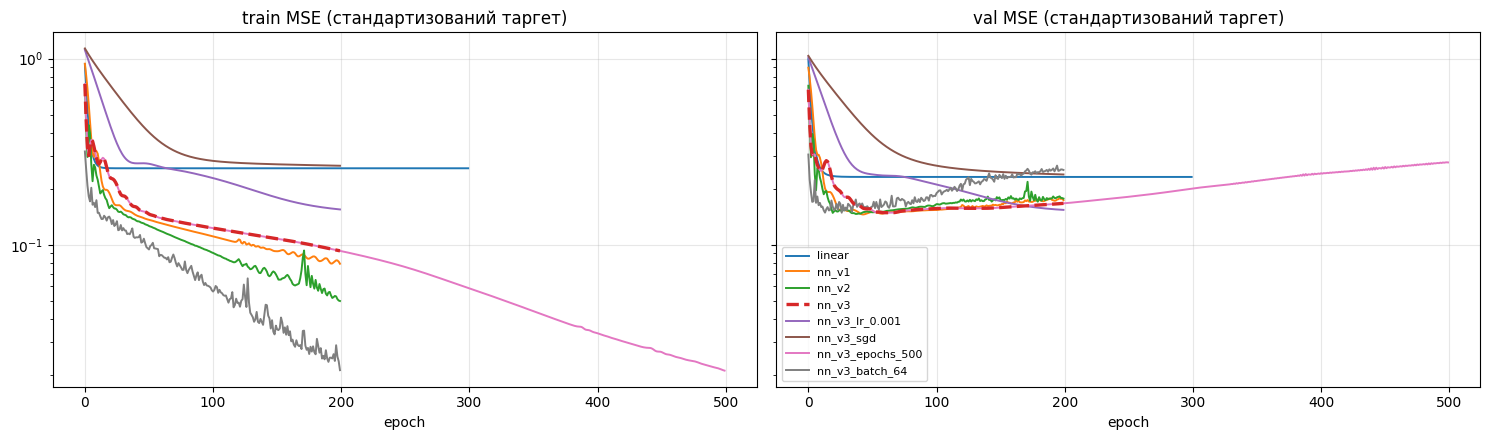

In [23]:
if IN_COLAB:
    get_ipython().run_line_magic("load_ext", "tensorboard")
    get_ipython().run_line_magic("tensorboard", f"--logdir {RUNS_DIR}")
else:
    print("Локально: tensorboard --logdir", RUNS_DIR)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for name, h in histories.items():
    kw = dict(ls="--", lw=2.4, zorder=5) if name == "nn_v3" else dict(lw=1.4)   # nn_v3 збігається з nn_v3_epochs_500 перші 200 епох
    axes[0].plot(h["train"], label=name, **kw); axes[1].plot(h["val"], label=name, **kw)
for ax, t in zip(axes, ["train MSE", "val MSE"]):
    ax.set_title(t + " (стандартизований таргет)"); ax.set_xlabel("epoch"); ax.set_yscale("log"); ax.grid(alpha=0.3)
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

In [24]:
results_full = pd.DataFrame(all_rows).set_index("model")
print("Повна таблиця (val MSE в стандартизованих одиницях, test-метрики в доларах):")
display(results_full.round(4))

# results.csv: рівно ті колонки, що вимагає лаба
results = results_full[["MSE", "RMSE", "MAE", "R2"]].reset_index()
results.to_csv("results.csv", index=False)
print("\nЗбережено results.csv:", results.shape)
results.round(4)

Повна таблиця (val MSE в стандартизованих одиницях, test-метрики в доларах):


,change,val_MSE(std),best_val_epoch,epochs,MSE,RMSE,MAE,R2
model,,,,,,,,
linear,baseline: множинна лінійна регресія,0.2315,168,300,3.746628e+07,6120.9702,4465.5025,0.7585
nn_v1,"архітектура 64-32, ReLU",0.1737,44,200,2.587915e+07,5087.1550,3327.7383,0.8332
nn_v2,"архітектура 128-64-32, ReLU",0.1772,38,200,3.034006e+07,5508.1809,3379.2333,0.8044
nn_v3,"архітектура 64-32, Tanh",0.1670,60,200,2.770715e+07,5263.7579,3314.5675,0.8214
nn_v3_lr_0.001,lr: 0.01 → 0.001,0.1541,200,200,2.419550e+07,4918.8926,3034.3020,0.8440
nn_v3_sgd,оптимізатор: Adam → SGD (lr 0.01),0.2387,200,200,3.826577e+07,6185.9335,4394.4015,0.7533
nn_v3_epochs_500,епохи: 200 → 500,0.2771,60,500,5.200552e+07,7211.4855,4880.2630,0.6647
nn_v3_batch_64,батч: весь train → 64,0.2524,27,200,4.078608e+07,6386.3982,4267.1151,0.7371



Збережено results.csv: (8, 5)


,model,MSE,RMSE,MAE,R2
0,linear,3.746628e+07,6120.9702,4465.5025,0.7585
1,nn_v1,2.587915e+07,5087.1550,3327.7383,0.8332
2,nn_v2,3.034006e+07,5508.1809,3379.2333,0.8044
3,nn_v3,2.770715e+07,5263.7579,3314.5675,0.8214
4,nn_v3_lr_0.001,2.419550e+07,4918.8926,3034.3020,0.8440
5,nn_v3_sgd,3.826577e+07,6185.9335,4394.4015,0.7533
6,nn_v3_epochs_500,5.200552e+07,7211.4855,4880.2630,0.6647
7,nn_v3_batch_64,4.078608e+07,6386.3982,4267.1151,0.7371


Пояснення колонок: `val_MSE(std)` це MSE на валідації (стандартизований таргет) для моделі *після останньої епохи*; `best_val_epoch` це епоха з мінімальним val MSE. Якщо вона набагато менша за `epochs`, мережа далі перенавчалась. Метрики `MSE/RMSE/MAE/R2` це test, у доларах. Варіанти обирались за val, а test використовується тільки для фінальної оцінки.

In [25]:
winner_val = min(histories, key=lambda n: histories[n]["val"][-1])
winner_test = results_full["MSE"].idxmin()
print("Найкращий за val MSE :", winner_val)
print("Найкращий за test MSE:", winner_test)
lin_r, win_r = results_full.loc["linear"], results_full.loc[winner_test]
print(f"\nЛінійна → найкраща модель: RMSE ${lin_r['RMSE']:,.0f} → ${win_r['RMSE']:,.0f} "
      f"({1 - win_r['RMSE']/lin_r['RMSE']:.0%} менше), MAE ${lin_r['MAE']:,.0f} → ${win_r['MAE']:,.0f}, "
      f"R² {lin_r['R2']:.3f} → {win_r['R2']:.3f}")

Найкращий за val MSE : nn_v3_lr_0.001
Найкращий за test MSE: nn_v3_lr_0.001

Лінійна → найкраща модель: RMSE $6,121 → $4,919 (20% менше), MAE $4,466 → $3,034, R² 0.758 → 0.844


#### 2.5.1. Контроль: що, якби додати взаємодію вручну?

Не входить у `results.csv`, це перевірка чесності висновку. Аналітичний МНК на тих самих train/test, але з доданими вручну ознаками `smoker × bmi` і `smoker × (bmi ≥ 30)`.

In [26]:
def add_interactions(d):
    e = encode(d)
    e["smoker_x_bmi"] = e["smoker_yes"] * e["bmi"]
    e["smoker_x_obese"] = e["smoker_yes"] * (e["bmi"] >= 30).astype(float)
    return e

ols_fe = LinearRegression().fit(add_interactions(train_df), train_df["charges"])
fe_metrics = regression_metrics(y_test_usd, ols_fe.predict(add_interactions(test_df)))
ols_plain = LinearRegression().fit(encode(train_df), train_df["charges"])
plain_metrics = regression_metrics(y_test_usd, ols_plain.predict(encode(test_df)))
pd.DataFrame({"МНК без взаємодій": plain_metrics, "МНК + smoker×bmi, smoker×obese": fe_metrics}).T.round(4)

,MSE,RMSE,MAE,R2
МНК без взаємодій,3.746628e+07,6120.9702,4465.5027,0.7585
"МНК + smoker×bmi, smoker×obese",2.062621e+07,4541.6088,2508.3639,0.8670


#### 2.5.2. Наскільки суттєві відмінності: стійкість до початкової ініціалізації

Усі числа вище отримані з **одного** seed на валідації з 268 рядків, тож невеликі різниці між варіантами можуть бути просто шумом ініціалізації. Перевіряємо ключові варіанти на 5 різних seed (спліт даних той самий, змінюється лише ініціалізація ваг). Це діагностика, і в `results.csv`, `runs/` та `models/` вона не потрапляє.

In [27]:
SEEDS = [0, 1, 2, 3, 4]
best_hyper_name = f"{best_arch}_lr_0.001"
check_specs = {"linear": LINEAR_SPEC, "nn_v1": ARCHS["nn_v1"], "nn_v2": ARCHS["nn_v2"],
               "nn_v3": ARCHS["nn_v3"], best_hyper_name: HYPER[best_hyper_name][0]}
rows = []
for name, spec in check_specs.items():
    per_seed = []
    for sd in SEEDS:
        m_, _ = train_variant("tmp", spec, log=False, seed=sd)
        per_seed.append(regression_metrics(y_test_usd, predict_usd(m_, x_test_t)))
    rows.append({"model": name,
                 "RMSE mean": np.mean([r["RMSE"] for r in per_seed]), "RMSE std": np.std([r["RMSE"] for r in per_seed]),
                 "R2 mean": np.mean([r["R2"] for r in per_seed]), "R2 std": np.std([r["R2"] for r in per_seed])})
seed_df = pd.DataFrame(rows).set_index("model")
seed_df.round(4)

,RMSE mean,RMSE std,R2 mean,R2 std
model,,,,
linear,6120.9702,0.0000,0.7585,0.0000
nn_v1,5074.0878,181.3645,0.8338,0.0119
nn_v2,5233.2488,204.4656,0.8232,0.0140
nn_v3,5184.8913,32.6797,0.8267,0.0022
nn_v3_lr_0.001,4877.5828,50.9285,0.8466,0.0032


### Підсумок порівняння

**Яка модель перемогла і наскільки суттєво?**
Найкраща модель — `nn_v3_lr_0.001` (Tanh, 64 → 32, Adam, lr = 0.001): вона перемагає і за val MSE (за яким ми обирали), і за test MSE. На test: RMSE **$4 919** проти $6 121 у лінійної регресії (на 20% менше), MAE **$3 034** проти $4 466 (на 32% менше), R² **0.844** проти 0.758. Усі моделі значно кращі за бейзлайн «середнє train» (RMSE $12 495, R² ≈ 0). Перевірка на 5 seed (2.5.2) показує, що цей виграш не випадковий: RMSE найкращого варіанта 4 878 ± 51 проти 6 121 у лінійної, і різниця на порядок більша за розкид між seed. А ось відмінності між трьома архітектурами (RMSE 5 074 ± 181, 5 233 ± 204 і 5 185 ± 33) лежать у межах розкиду. Тому вибір `nn_v3` за val по одному seed значною мірою випадковий (на test одного прогону з трьох архітектур найкращою була `nn_v1`), і робити висновок «Tanh краща за ReLU» не варто.

**Чи виправдала себе нейромережа порівняно з лінійною регресією?**
Порівняно з простою лінійною регресією так: у даних є нелінійність (взаємодія `smoker × bmi`, видна в EDA), і мережа її вловлює. Але контроль 2.5.1 додає важливе застереження: якщо додати в лінійну модель вручну дві ознаки-взаємодії, вона дає RMSE $4 542, MAE $2 508 і R² 0.867, тобто перемагає **усі** варіанти нейромережі (найкращий: $4 919 / $3 034 / 0.844). Отже, головний виграш мережі це знайдена нею взаємодія, яку можна було відкрити в EDA й закласти вручну, отримавши простішу, швидшу й інтерпретовану модель. На цьому маленькому датасеті (1 338 рядків, 6 ознак) нейромережа не є обов'язковим інструментом, хоча її можна було б ще донастроїти. (Контроль 2.5.1 це діагностичний одноразовий прогін на test, модель за ним не обиралась.)

**Що з наших змін дало найбільший ефект?**
- **Найбільший позитивний ефект: менший learning rate.** `nn_v3`, lr 0.01 → 0.001: test RMSE $5 264 → $4 919 (−7%), val MSE 0.167 → 0.154. При lr = 0.01 Adam із повним train за крок досягає мінімуму val вже за ≈ 40–60 епох (колонка `best_val_epoch`) і далі перенавчається, а з lr = 0.001 val ще спадає до кінця 200 епох.
- **Найбільший негативний ефект: надто багато кроків оптимізації.** 500 епох (RMSE $7 211, +37%) і батч 64 (RMSE $6 386, +21%; ≈ 13 оновлень за епоху замість одного) призводять до перенавчання: мінімум val на 60-й і 27-й епохах відповідно, далі train падає, а val росте. Практичний висновок: потрібен early stopping за val, а «200 епох» не є універсально правильною кількістю.
- **SGD замість Adam** (той самий lr = 0.01) недонавчається: RMSE $6 186 майже збігається з лінійною моделлю, бо повільний SGD за 200 епох не встигає вивчити нелінійність.
- **Зміна архітектури** (глибша й ширша `nn_v2`, або Tanh замість ReLU) дала різницю, що не виходить за розкид між seed. Тому основні рішення тут про процес тренування, а не про кількість шарів.

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

Аппка завантажує **усі збережені `.pt`-файли** з `models/` (а не моделі з пам'яті), приймає значення ознак клієнта у вихідному вигляді (вік, ІМТ, кількість дітей, стать, курець, регіон), проводить їх через ті самі кодування й стандартизацію, що й при тренуванні, і показує прогноз вибраної моделі та стовпчикове порівняння всіх варіантів.

In [28]:
import glob
import gradio as gr

def load_model(path):
    ckpt = torch.load(path, map_location="cpu")
    m = make_mlp(ckpt["n_in"], ckpt["hidden"], ckpt["activation"])
    m.load_state_dict(ckpt["state_dict"]); m.eval()
    return m

models = {os.path.splitext(os.path.basename(p))[0]: load_model(p)
          for p in sorted(glob.glob(os.path.join(MODELS_DIR, "*.pt")))}
print("Завантажено з models/:", list(models))

# Перевірка: моделі, завантажені з файлів, дають ті самі прогнози, що й тренувальні в пам'яті
for name, m in models.items():
    assert np.allclose(predict_usd(m, x_test_t), predict_usd(trained[name], x_test_t), atol=1e-3), name
print("Перевірка збереження/завантаження: ОК")

Завантажено з models/: ['linear', 'nn_v1', 'nn_v2', 'nn_v3', 'nn_v3_batch_64', 'nn_v3_epochs_500', 'nn_v3_lr_0.001', 'nn_v3_sgd']
Перевірка збереження/завантаження: ОК


In [29]:
def predict_all(age, bmi, children, sex, smoker, region):
    row = pd.DataFrame([{"age": age, "bmi": bmi, "children": int(children),
                         "sex": sex, "smoker": smoker, "region": region}])
    x = to_t(x_scaler.transform(encode(row)))
    return {name: float(predict_usd(m, x)[0]) for name, m in models.items()}

def run_prediction(selected, age, bmi, children, sex, smoker, region):
    preds = predict_all(age, bmi, children, sex, smoker, region)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    names = list(preds)
    bars = ax.bar(names, [preds[n] for n in names],
                  color=["#C44E52" if n == selected else "#4C72B0" for n in names])
    ax.set_ylabel("Прогноз charges, $"); ax.set_title("Порівняння всіх варіантів для цього клієнта")
    plt.xticks(rotation=35, ha="right"); plt.tight_layout()
    plt.close(fig)
    return round(preds[selected], 2), fig

# Швидка перевірка логіки без UI: курець/некурець з однаковими іншими ознаками
for smk in ("no", "yes"):
    p = predict_all(40, 32.0, 2, "male", smk, "northeast")
    print(f"smoker={smk:3s} ->", {k: round(v) for k, v in list(p.items())[:3]}, "...")

smoker=no  -> {'linear': 10124, 'nn_v1': 14063, 'nn_v2': 10737} ...
smoker=yes -> {'linear': 33539, 'nn_v1': 32655, 'nn_v2': 30114} ...


In [30]:
with gr.Blocks(title="Medical Insurance Cost: порівняння моделей") as demo:
    gr.Markdown("## Прогноз вартості страхування: лінійна регресія проти нейромереж")
    with gr.Row():
        with gr.Column():
            model_choice = gr.Dropdown(choices=list(models), value=best_arch if best_arch in models else list(models)[0],
                                       label="Основна модель")
            age = gr.Slider(18, 64, value=40, step=1, label="age")
            bmi = gr.Slider(15, 54, value=30, step=0.1, label="bmi")
            children = gr.Slider(0, 5, value=1, step=1, label="children")
            sex = gr.Radio(["female", "male"], value="male", label="sex")
            smoker = gr.Radio(["no", "yes"], value="no", label="smoker")
            region = gr.Dropdown(REGIONS, value=REGIONS[0], label="region")
            btn = gr.Button("Порахувати прогноз", variant="primary")
        with gr.Column():
            out_number = gr.Number(label="Прогноз обраної моделі, $")
            out_plot = gr.Plot(label="Порівняння всіх варіантів")
    inputs = [model_choice, age, bmi, children, sex, smoker, region]
    btn.click(run_prediction, inputs=inputs, outputs=[out_number, out_plot])

_, local_url, _ = demo.launch(share=IN_COLAB, prevent_thread_lock=True)   # не блокує Run All

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Наскрізна перевірка: викликаємо запущену аппку через її API так, як це робив би користувач у браузері.

In [31]:
try:
    from gradio_client import Client
    api = Client(local_url, verbose=False)
    res = api.predict(best_hyper_name, 40, 32.0, 2, "male", "yes", "northeast", api_name="/run_prediction")
    print(f"Gradio API ({best_hyper_name}), курець, 40 років, bmi 32: прогноз = ${res[0]:,.0f}")
except Exception as e:
    print("Перевірку через API пропущено:", e)

Gradio API (nn_v3_lr_0.001), курець, 40 років, bmi 32: прогноз = $36,508


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. **Відео демонстрації TensorBoard & Gradio-застосунку** замість скріншотів цього разу: 60-90 секунд. На відео показуєте тренування і роботу моделей і коротко розповідаєте про цікаве (можливості, обмеження, труднощі тренування).
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
/lab2/demo.mp4
```